# Регуляризация в регрессии

**Регуляризация** - метод предотвращение переобучения путем штрафа за большие коэффициенты модели

### Lasso Regression(L1) - Least Absolute Shrinkage and Selection Operator

Штраф: сумма модулей весов
$$
min(\sum{(y - \hat{y})^2} + \lambda\sum{|w_i|})
$$

Эффект:
- может занулить коэффициенты
- делает feature selection


### Ridge Regression(L2) - "Гребневая регрессия"

Штраф: сумма квадратов весов
$$
min(\sum{(y - \hat{y})^2} + \lambda\sum{{w_i}^2})
$$

Эффект:
- уменьшает веса
- **НЕ** зануляет признаки
- дает стабильную модель

### Когда что использовать?

| Модель            | Когда                                                |
|-------------------|------------------------------------------------------|
| Lasso(L1)         | Надо выбирать важные признаки                        |
| Ridge(L2)         | Много признаков, нужны все                           |
| ElasticNet(L1+L2) | Смесь L1 и L2, полезно при коррелированных признаках |


In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
from matplotlib import scale

from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from  sklearn.metrics import r2_score, root_mean_squared_error
from sklearn.model_selection import train_test_split

In [2]:
np.random.seed(42)
n = 120
X = np.linspace(-4, 6, n).reshape(-1, 1)
noise = np.random.normal(0, 6, n)

y = 0.5 * X[:,0]**3 - 3 * X[:,0]**2 + 2 * X[:,0] + noise

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

In [4]:
def train_model(model, name):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    print(f"""
    === {name} ===
    R2_score:   {r2_score(y_test, y_pred):.2f}
    RMSE:       {root_mean_squared_error(y_test, y_pred):.2f}
""")
    return model

In [11]:
degree = 10
lasso = Pipeline([
    ('poly', PolynomialFeatures(degree=degree, include_bias=False)),
    ('scaler', StandardScaler()),
    ('lasso', Lasso(alpha=0.5, max_iter=1000)),
])

ridge = Pipeline([
    ('poly', PolynomialFeatures(degree=degree, include_bias=False)),
    ('scaler', StandardScaler()),
    ('ridge', Ridge(alpha=1.0)),
])

elastic_net = Pipeline([
    ('poly', PolynomialFeatures(degree=degree, include_bias=False)),
    ('scaler', StandardScaler()),
    ('elastic_net', ElasticNet(alpha=0.05, max_iter=1000, l1_ratio=0.3)),
])

lasso = train_model(lasso, 'lasso')
ridge = train_model(ridge, 'ridge')
elastic_net = train_model(elastic_net, 'elastic_net')


    === lasso ===
    R2_score:   0.94
    RMSE:       6.16


    === ridge ===
    R2_score:   0.95
    RMSE:       5.61


    === elastic_net ===
    R2_score:   0.93
    RMSE:       6.51



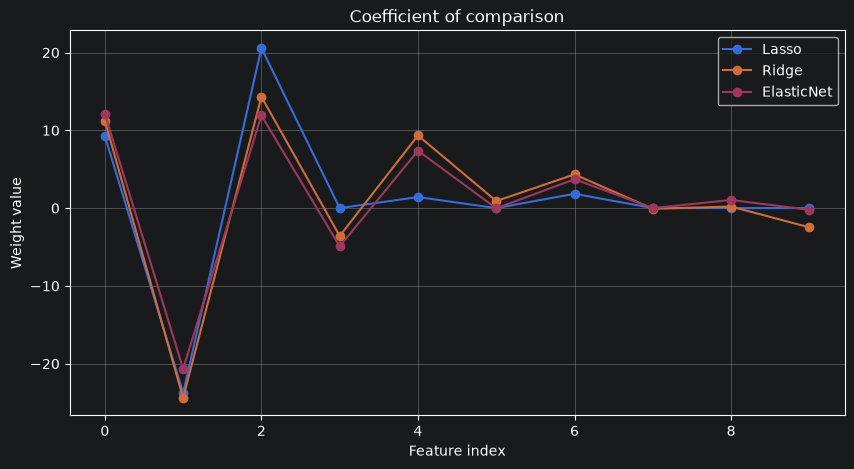

In [12]:
models = {
    "Lasso": lasso.named_steps['lasso'].coef_,
    "Ridge": ridge.named_steps['ridge'].coef_,
    "ElasticNet": elastic_net.named_steps['elastic_net'].coef_,
}

plt.figure(figsize=(10, 5))
for name, coef in models.items():
    plt.plot(coef, label=name, marker='o')
plt.title("Coefficient of comparison")
plt.xlabel('Feature index')
plt.ylabel('Weight value')
plt.legend()
plt.grid(True)
plt.show()